# EDA на прокси-датасетах: запросы клиентов к банку и короткие русские запросы

> **Первая версия EDA (дополнительный анализ).** Основной EDA — [`02_eda_search_proxies.ipynb`](02_eda_search_proxies.ipynb): там прокси с разметкой пар «запрос–документ» (WANDS, ESCI LLM-judged), метрики на реальной выдаче и синтетический каталог фич банка. Синтетическая выдача из раздела 5 этого ноутбука заменена просадками на выдаче WANDS. Здесь остаются свойства текста: опечатки, морфология, дубли, согласие разметчиков MASSIVE.

> **Прокси до получения данных банка.** Реальных запросов, выдачи и разметки Альфа-Банка у команды пока нет: первые примеры разметки ожидаются до 13.11.2026, полный набор — к 20.11.2026. Здесь анализируются публичные датасеты, которые похожи на будущие данные по отдельным свойствам. Выводы о данных банка — это **гипотезы**, которые нужно перепроверить на реальной выгрузке (раздел 7 ноутбука запускается на ней без изменений).

**Что берём и зачем:**

| Датасет | Что это | Какое свойство данных банка моделирует |
| --- | --- | --- |
| [BANKING77](https://huggingface.co/datasets/PolyAI/banking77) | 13 083 англоязычных обращения клиентов банка, 77 интентов | Банковские интенты: баланс классов, близкие и путающиеся интенты, синонимы, опечатки |
| [MASSIVE 1.1, ru-RU](https://github.com/alexa/massive) | 16 521 короткая русская команда голосовому ассистенту, 60 интентов, 3 оценки разметчиков на пример | Русский язык: длина, морфология, латиница и бренды, дубли с разной меткой, согласие разметчиков |
| Синтетическая выдача (раздел 5) | Сгенерированные запросы, каталог фич и ранжирование | Поведение метрик R3, NDCG@3 и детектора просадок при ошибках судьи |

Ни один датасет не содержит **выдачу** поиска. Поэтому свойства выдачи (позиции, топ-3, просадки) смотрим только на явно помеченной синтетике.

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

from mlsd_course.eda.loaders import load_banking77, load_massive_ru
from mlsd_course.eda.ranking import query_metrics
from mlsd_course.eda.synthetic import drop_detection_quality, inject_release, make_serp
from mlsd_course.eda.text_stats import (
    LAT_RE,
    duplicates_report,
    intent_similarity,
    normalize,
    script_mix,
    tokens,
    top_pairs,
    typo_candidates,
    wilson_halfwidth,
)

FIG = Path("../reports/eda")
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140)
SEED = 42


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight")
    plt.show()

## 1. Состав и объём данных

In [2]:
b77 = load_banking77()
ru = load_massive_ru()
b77["n_words"] = b77["text"].map(lambda t: len(tokens(t)))
ru["n_words"] = ru["text"].map(lambda t: len(tokens(t)))

summary = pd.DataFrame(
    {
        "BANKING77": {
            "строк": len(b77),
            "интентов": b77["intent"].nunique(),
            "сплиты": b77["split"].value_counts().to_dict(),
            "пропуски в text": int(b77["text"].isna().sum()),
            "пустые строки": int((b77["text"].str.strip() == "").sum()),
        },
        "MASSIVE ru-RU": {
            "строк": len(ru),
            "интентов": ru["intent"].nunique(),
            "сплиты": ru["split"].value_counts().to_dict(),
            "пропуски в text": int(ru["text"].isna().sum()),
            "пустые строки": int((ru["text"].str.strip() == "").sum()),
        },
    }
)
summary

,BANKING77,MASSIVE ru-RU
строк,13083,16521
интентов,77,60
сплиты,"{'train': 10003, 'test': 3080}","{'train': 11514, 'test': 2974, 'dev': 2033}"
пропуски в text,0,0
пустые строки,0,0


In [3]:
ru[["id", "scenario", "intent", "text", "split"]].head(5)

,id,scenario,intent,text,split
0,0,alarm,alarm_set,разбуди меня в пять утра на этой неделе,test
1,1,alarm,alarm_set,разбуди меня в девять утра в пятницу,train
2,2,alarm,alarm_set,поставь будильник на два часа вперед,train
3,3,audio,audio_volume_mute,тише,test
4,4,audio,audio_volume_mute,олли тихо,train


### 1.1. Баланс интентов

                   min    50%    max  max/min
BANKING77 train   35.0  127.0  187.0      5.3
MASSIVE ru train   4.0  128.5  810.0    202.5
BANKING77 test: примеров на интент [40]
Самые редкие интенты BANKING77: {'lost_or_stolen_card': 82, 'card_swallowed': 61, 'card_acceptance': 59, 'virtual_card_not_working': 41, 'contactless_not_working': 35}
Самые редкие интенты MASSIVE ru: {'general_greet': 25, 'iot_hue_lighton': 22, 'audio_volume_other': 18, 'music_dislikeness': 14, 'cooking_query': 4}
Интентов MASSIVE с < 50 примерами в train: 6
Интентов BANKING77 с < 50 примерами в train: 2


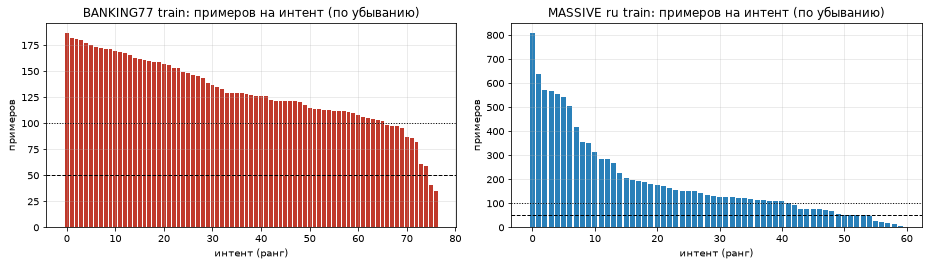

In [4]:
b_tr = b77[b77["split"] == "train"]["intent"].value_counts()
r_tr = ru[ru["split"] == "train"]["intent"].value_counts()
bal = pd.DataFrame(
    {
        "BANKING77 train": b_tr.describe()[["min", "50%", "max"]],
        "MASSIVE ru train": r_tr.describe()[["min", "50%", "max"]],
    }
).T
bal["max/min"] = bal["max"] / bal["min"]
print(bal.round(1))
print(
    "BANKING77 test: примеров на интент",
    b77[b77["split"] == "test"]["intent"].value_counts().unique(),
)
print("Самые редкие интенты BANKING77:", b_tr.tail(5).to_dict())
print("Самые редкие интенты MASSIVE ru:", r_tr.tail(5).to_dict())
print("Интентов MASSIVE с < 50 примерами в train:", int((r_tr < 50).sum()))
print("Интентов BANKING77 с < 50 примерами в train:", int((b_tr < 50).sum()))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(range(len(b_tr)), b_tr.values, color="#c0392b")
ax[0].set_title("BANKING77 train: примеров на интент (по убыванию)")
ax[0].axhline(50, ls="--", c="k", lw=1)
ax[0].axhline(100, ls=":", c="k", lw=1)
ax[1].bar(range(len(r_tr)), r_tr.values, color="#2980b9")
ax[1].set_title("MASSIVE ru train: примеров на интент (по убыванию)")
ax[1].axhline(50, ls="--", c="k", lw=1)
ax[1].axhline(100, ls=":", c="k", lw=1)
for a in ax:
    a.set_xlabel("интент (ранг)")
    a.set_ylabel("примеров")
save(fig, "01_intent_balance.png")

**Выводы.**
- В BANKING77 train дисбаланс умеренный: от 35 до 187 примеров на интент (в 5,3 раза), test сбалансирован ровно по 40. В MASSIVE ru дисбаланс сильный: от 4 до 810 примеров (в 202 раза).
- Линии на графике — 50 и 100 примеров, плановый объём разметки банка на интент. Не дотягивают до 50 два интента BANKING77 и шесть интентов MASSIVE ru, то есть «длинный хвост» редких интентов — типичная картина.
- **Для разметки банка:** объём нужно задавать не «в среднем на интент», а с минимумом на каждый интент, и сэмплировать стратифицированно по интентам, иначе редкие интенты в отложенной части окажутся почти пустыми.

### 1.2. Длина запросов

              count  mean  std  min  25%   50%   75%   max
BANKING77   13083.0  12.0  7.9  2.0  7.0  10.0  13.0  84.0
MASSIVE ru  16521.0   5.9  3.0  1.0  4.0   5.0   7.0  58.0
BANKING77: <=2 слов 0.1%, <=3 слов 0.3%, >20 слов 10.6%
MASSIVE ru: <=2 слов 7.6%, <=3 слов 19.4%, >20 слов 0.1%


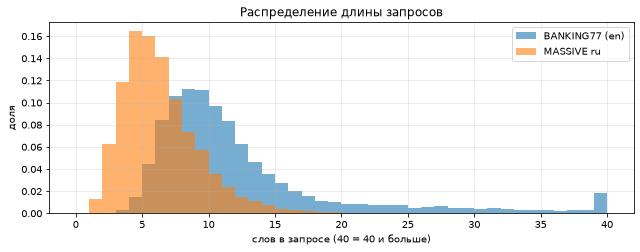

In [5]:
print(
    pd.DataFrame({"BANKING77": b77["n_words"].describe(), "MASSIVE ru": ru["n_words"].describe()})
    .round(1)
    .T
)
for name, df in [("BANKING77", b77), ("MASSIVE ru", ru)]:
    s = df["n_words"]
    print(
        f"{name}: <=2 слов {(s <= 2).mean():.1%}, <=3 слов {(s <= 3).mean():.1%}, >20 слов {(s > 20).mean():.1%}"
    )

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 41)
ax.hist(b77["n_words"].clip(upper=40), bins=bins, alpha=0.6, density=True, label="BANKING77 (en)")
ax.hist(ru["n_words"].clip(upper=40), bins=bins, alpha=0.6, density=True, label="MASSIVE ru")
ax.set_xlabel("слов в запросе (40 = 40 и больше)")
ax.set_ylabel("доля")
ax.set_title("Распределение длины запросов")
ax.legend()
save(fig, "02_query_length.png")

**Выводы.**
- BANKING77 — это развёрнутые обращения в поддержку: медиана 10 слов, 10,6% длиннее 20 слов. MASSIVE ru — короткие команды: медиана 5 слов, 19,4% не длиннее 3 слов. Поисковые запросы в приложении банка, скорее всего, ещё короче: 1–3 слова вроде «вклад» или «перевод по номеру» (**допущение**, проверить на данных банка).
- Чем короче запрос, тем меньше в нём контекста и тем чаще он неоднозначен: «карта» может означать дебетовую, кредитную или перевыпуск. **Для оценщика:** короткие неоднозначные запросы — отдельная страта, для них разметка должна допускать несколько релевантных фич, а судья должен иметь право ответить «неоднозначно» и отдать случай человеку.
- По длине MASSIVE ru ближе к поисковым запросам, чем BANKING77, поэтому языковые выводы берём из него, а выводы про банковские интенты — из BANKING77.

## 2. Качество данных: дубли, конфликты меток, шум

### 2.1. Дубли и одинаковые запросы с разными интентами

In [6]:
rep_b = duplicates_report(b77)
rep_r = duplicates_report(ru)
print(pd.DataFrame({"BANKING77": rep_b, "MASSIVE ru": rep_r}).drop("conflict_examples").T)
print()
print("BANKING77, одинаковый текст — разные интенты:", rep_b["conflict_examples"])
print("MASSIVE ru, одинаковый текст — разные интенты:", rep_r["conflict_examples"])

b_norm_tr = set(b77.loc[b77["split"] == "train", "text"].map(normalize))
leak_b = b77.loc[b77["split"] == "test", "text"].map(normalize).isin(b_norm_tr).sum()
r_norm_tr = set(ru.loc[ru["split"] == "train", "text"].map(normalize))
leak_r = ru.loc[ru["split"] == "test", "text"].map(normalize).isin(r_norm_tr).sum()
print(f"Тестовые запросы, дословно встречающиеся в train: BANKING77 {leak_b}, MASSIVE ru {leak_r}")

           n_rows n_unique_norm n_dup_groups n_rows_in_dup_groups n_conflict_groups n_rows_in_conflict_groups
BANKING77   13083         13023           60                  120                 2                         4
MASSIVE ru  16521         15600          534                 1455                36                       153

BANKING77, одинаковый текст — разные интенты: ['has my top up gone through', 'what are the fees for top ups']
MASSIVE ru, одинаковый текст — разные интенты: ['выключи свет', 'включи пылесос', 'включи музыку', 'включи свет', 'какое сегодня число', 'выключи', 'что мне нужно сделать сегодня', 'пожалуйста выключи розетку wemo', 'расскажи шутку', 'тише']
Тестовые запросы, дословно встречающиеся в train: BANKING77 25, MASSIVE ru 208


In [7]:
norm = ru["text"].map(normalize)
conf = (
    ru.assign(norm=norm)
    .groupby("norm")["intent"]
    .agg(["size", "nunique", lambda s: sorted(set(s))])
)
conf.columns = ["строк", "интентов", "какие интенты"]
conf[conf["интентов"] > 1].sort_values("строк", ascending=False).head(8)

,строк,интентов,какие интенты
norm,,,
выключи свет,31,3,"[iot_hue_lightdim, iot_hue_lightoff, iot_hue_l..."
включи пылесос,22,2,"[iot_cleaning, iot_wemo_on]"
включи музыку,9,2,"[play_music, play_radio]"
включи свет,9,2,"[iot_hue_lighton, iot_hue_lightup]"
какое сегодня число,9,2,"[calendar_query, datetime_query]"
выключи,4,2,"[iot_hue_lightoff, iot_wemo_off]"
что мне нужно сделать сегодня,4,3,"[calendar_remove, general_quirky, lists_query]"
пожалуйста выключи розетку wemo,4,2,"[iot_wemo_off, iot_wemo_on]"


**Выводы.**
- В MASSIVE ru 1 455 строк (8,8%) входят в 534 группы дословных дублей после нормализации. В 36 группах (153 строки) один и тот же текст размечен разными интентами: «выключи свет» встречается 31 раз с тремя разными интентами. Это не всегда ошибка: без контекста короткий запрос объективно неоднозначен. В BANKING77 с длинными запросами таких групп всего 2.
- 208 тестовых запросов MASSIVE ru и 25 тестовых BANKING77 дословно встречаются в train. Если наивно делить разметку банка случайно, оценщик будет «настраиваться» и «проверяться» на одних и тех же запросах.
- **Для данных банка:** частые запросы повторяются по определению (BRD говорит о частых запросах). Поэтому (1) делим на части **по нормализованному тексту запроса**, а не по строкам; (2) единица оценки — уникальная пара «запрос + платформа + версия», дубли схлопываем; (3) конфликтующие метки на одинаковом тексте отдаём на повторную разметку и считаем меру неоднозначности.

### 2.2. Опечатки

In [8]:
typo_b = typo_candidates(b77["text"])
typo_r = typo_candidates(ru["text"])
print(
    "Кандидатов в опечатки (редкое слово в 1 правке от частого): BANKING77",
    len(typo_b),
    "| MASSIVE ru",
    len(typo_r),
)
sample_b = typo_b.sample(40, random_state=0)
sample_r = typo_r.sample(30, random_state=0)
sample_b[["rare", "likely", "likely_count"]].head(15)

Кандидатов в опечатки (редкое слово в 1 правке от частого): BANKING77 211 | MASSIVE ru 572


,rare,likely,likely_count
173,reverts,revert,25
74,matercard,mastercard,139
12,paymet,payment,921
5,moeney,money,1407
55,receives,received,260
89,crying,trying,115
125,sold,old,56
194,clears,clear,15
52,currancy,currency,262
71,verifacation,verification,147


In [9]:
# Ручная проверка случайных выборок кандидатов: что из них настоящая опечатка.
# Остальное — легальные словоформы или другие слова (например, scan → can, кухня → кухне).
TRUE_TYPOS_B = {
    "matercard",
    "paymet",
    "moeney",
    "currancy",
    "verifacation",
    "attemped",
    "beneficiairy",
    "exhange",
    "ecchange",
    "transger",
    "withing",
    "companys",
}
TRUE_TYPOS_R = {"обемена", "напимсать", "dominos"}
prec_b = sample_b["rare"].isin(TRUE_TYPOS_B).mean()
prec_r = sample_r["rare"].isin(TRUE_TYPOS_R).mean()
print(
    f"Доля настоящих опечаток среди кандидатов: BANKING77 {prec_b:.0%} (n=40), MASSIVE ru {prec_r:.0%} (n=30)"
)
print(
    "Примеры ложных кандидатов MASSIVE ru:",
    sample_r.loc[~sample_r["rare"].isin(TRUE_TYPOS_R), ["rare", "likely"]].head(8).values.tolist(),
)

b_tok = Counter(t for s in b77["text"] for t in tokens(s))
for variants in [
    ("transfer", "tranfer", "trasfer", "transger"),
    ("exchange", "exhange", "exchage", "ecchange"),
]:
    print({v: b_tok.get(v, 0) for v in variants})

Доля настоящих опечаток среди кандидатов: BANKING77 30% (n=40), MASSIVE ru 10% (n=30)
Примеры ложных кандидатов MASSIVE ru: [['кухня', 'кухне'], ['спой', 'свой'], ['киноа', 'кино'], ['копить', 'купить'], ['лион', 'либо'], ['виде', 'видео'], ['разницы', 'разница'], ['темпы', 'темы']]
{'transfer': 1392, 'tranfer': 0, 'trasfer': 1, 'transger': 1}
{'exchange': 708, 'exhange': 1, 'exchage': 1, 'ecchange': 1}


**Выводы.**
- Эвристика нашла 211 кандидатов в BANKING77 и 572 в MASSIVE ru. По ручной проверке случайной выборки настоящие опечатки — 30% кандидатов в BANKING77 (`trasfer`, `exhange`, `paymet`) и только 10% в MASSIVE ru. Каждая опечатка встречается один раз на сотни и тысячи правильных написаний.
- В русском эвристика «одна правка от частого слова» в основном находит **другую словоформу или другое слово**, а не опечатку (`кухня → кухне`, `копить → купить`). Словоформ слишком много, поэтому edit distance для русского — плохой детектор опечаток и плохой способ сравнивать названия.
- **Для оценщика:** бейзлайн на точном совпадении строк ломается и на опечатках, и на морфологии. LLM-судья устойчивее, но в набор проверки нужно специально включить запросы с опечатками и раскладкой (например, «drkfl» вместо «вклад»), потому что клиенты в поиске пишут быстро.

### 2.3. Русская морфология, латиница и смешение языков (MASSIVE ru)

In [10]:
ru["script"] = ru["text"].map(script_mix)
print("Тип алфавита в запросе:", ru["script"].value_counts(normalize=True).round(4).to_dict())
lat = Counter(t for s in ru["text"] for t in tokens(s) if LAT_RE.search(t))
print("Уникальных латинских токенов:", len(lat))
print("Топ латинских токенов:", lat.most_common(15))
olly = ru["text"].str.contains(r"\bolly\b").sum()
print(f"Из них запросов с wake-word 'olly': {olly} ({olly / len(ru):.1%})")

ru_tok = Counter(t for s in ru["text"] for t in tokens(s) if not LAT_RE.search(t))
stems: dict[str, set[str]] = {}
for w in ru_tok:
    if len(w) >= 6:
        stems.setdefault(w[:5], set()).add(w)
forms = pd.Series({k: len(v) for k, v in stems.items()})
print(
    f"Псевдоосновы (первые 5 букв, слова от 6 букв): {len(forms)}, в среднем {forms.mean():.2f} формы, у {(forms >= 3).mean():.0%} — 3 и больше форм"
)
for key in ["напом", "будил", "перев", "плати"]:
    print(key, sorted(stems.get(key, []))[:10])
yo = [w for w in ru_tok if "ё" in w]
yo_pairs = [w for w in yo if w.replace("ё", "е") in ru_tok]
print(
    f"Слов с «ё»: {len(yo)}, из них встречаются и через «е»: {len(yo_pairs)}, например {yo_pairs[:6]}"
)

Тип алфавита в запросе: {'cyr': 0.9237, 'mixed': 0.0759, 'lat': 0.0004}
Уникальных латинских токенов: 304
Топ латинских токенов: [('olly', 368), ('facebook', 98), ('google', 95), ('alexa', 70), ('twitter', 62), ('b', 45), ('com', 41), ('gmail', 33), ('siri', 28), ('uber', 28), ('c', 27), ('s', 27), ('n', 27), ('pandora', 22), ('wemo', 21)]
Из них запросов с wake-word 'olly': 368 (2.2%)
Псевдоосновы (первые 5 букв, слова от 6 букв): 3772, в среднем 2.25 формы, у 25% — 3 и больше форм
напом ['напоми', 'напоминай', 'напоминание', 'напоминанием', 'напоминании', 'напоминаний', 'напоминания', 'напоминаниям', 'напоминаниях', 'напоминать']
будил ['будильник', 'будильника', 'будильниках', 'будильнике', 'будильники', 'будильников', 'будильником', 'будильнику']
перев ['переведи', 'перевернутую', 'перевести', 'переводчик']
плати ['платит', 'платить']
Слов с «ё»: 174, из них встречаются и через «е»: 74, например ['ковёр', 'идёт', 'зелёный', 'приглушённый', 'займёт', 'моё']


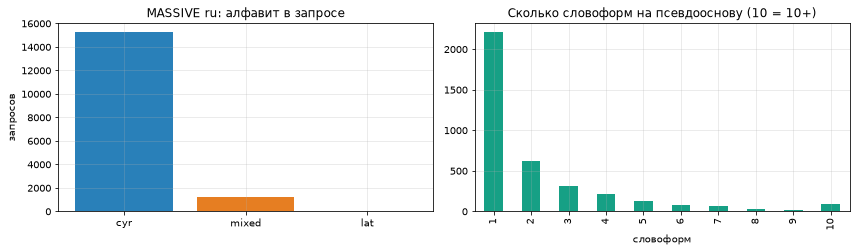

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sc = ru["script"].value_counts()
ax[0].bar(sc.index, sc.values, color=["#2980b9", "#e67e22", "#7f8c8d"][: len(sc)])
ax[0].set_title("MASSIVE ru: алфавит в запросе")
ax[0].set_ylabel("запросов")
forms.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax[1], color="#16a085")
ax[1].set_title("Сколько словоформ на псевдооснову (10 = 10+)")
ax[1].set_xlabel("словоформ")
save(fig, "03_ru_script_morphology.png")

**Выводы.**
- 7,6% русских запросов смешивают кириллицу и латиницу, а чисто латинских — 0,04%. Это в основном **бренды и сервисы** (`facebook`, `google`, `uber`) и wake-word `olly` (2,2% запросов). Для банка аналогами будут названия продуктов и партнёров (Alfa Travel, СБП, Apple Pay), а также запросы, набранные в неправильной раскладке.
- На одну псевдооснову приходится в среднем 2,25 словоформы, у 25% — три и больше (`будильник` встречается в восьми формах). 74 слова с «ё» встречаются и через «е». **Для оценщика и бейзлайна:** сравнивать запрос, интент и название фичи нужно по смыслу или хотя бы после лемматизации. Ещё нужна нормализация «ё/е» и регистра.

## 3. Интенты: лексическая близость и путаница

### 3.1. Близость центроидов интентов (TF-IDF, символьные n-граммы)

In [12]:
sim_b, _ = intent_similarity(b77)
pairs_b = top_pairs(sim_b, 12)
pairs_b

,intent_a,intent_b,cos
0,verify_my_identity,why_verify_identity,0.913911
1,disposable_card_limits,get_disposable_virtual_card,0.843162
2,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal,0.841014
3,unable_to_verify_identity,why_verify_identity,0.812485
4,exchange_charge,exchange_via_app,0.799626
5,unable_to_verify_identity,verify_my_identity,0.784048
6,getting_virtual_card,virtual_card_not_working,0.783674
7,get_disposable_virtual_card,virtual_card_not_working,0.775540
8,top_up_by_bank_transfer_charge,transfer_fee_charged,0.763654
9,Refund_not_showing_up,request_refund,0.750953


In [13]:
sim_r, _ = intent_similarity(ru)
top_pairs(sim_r, 10)

,intent_a,intent_b,cos
0,alarm_query,alarm_remove,0.833248
1,alarm_remove,alarm_set,0.831943
2,iot_wemo_off,iot_wemo_on,0.829783
3,alarm_query,alarm_set,0.786865
4,calendar_query,calendar_set,0.718622
5,audio_volume_down,audio_volume_up,0.701223
6,takeaway_order,takeaway_query,0.682695
7,calendar_query,general_quirky,0.680874
8,general_quirky,qa_factoid,0.675488
9,iot_hue_lighton,iot_hue_lightup,0.653682


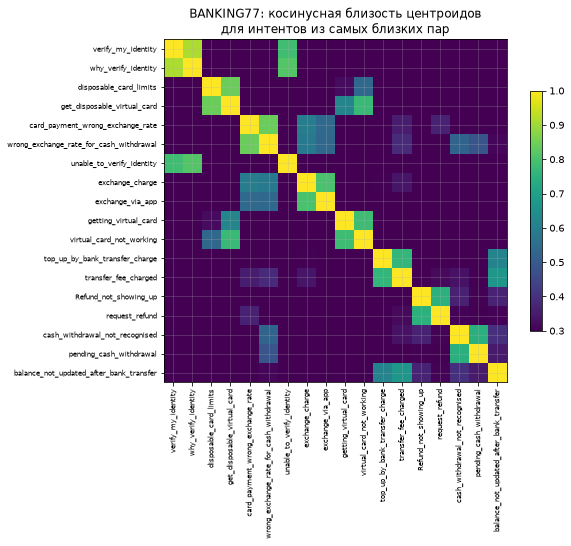

In [14]:
top_int = pd.unique(pairs_b[["intent_a", "intent_b"]].values.ravel())[:18]
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(sim_b.loc[top_int, top_int].values, cmap="viridis", vmin=0.3, vmax=1)
ax.set_xticks(range(len(top_int)), top_int, rotation=90, fontsize=7)
ax.set_yticks(range(len(top_int)), top_int, fontsize=7)
ax.set_title("BANKING77: косинусная близость центроидов\nдля интентов из самых близких пар")
fig.colorbar(im, ax=ax, shrink=0.7)
save(fig, "04_intent_similarity_heatmap.png")

### 3.2. Какие интенты путает простой классификатор

Линейная модель на TF-IDF — это не наш оценщик, а «линейка» сложности данных. Если простой классификатор путает пару интентов, то и классификатор поиска банка, скорее всего, будет путать похожие фичи, а разметчики будут расходиться во мнениях.

In [15]:
def tfidf_lr(train, test):
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
    xtr = vec.fit_transform(train["text"].str.lower())
    xte = vec.transform(test["text"].str.lower())
    clf = LogisticRegression(max_iter=2000, C=10)
    clf.fit(xtr, train["intent"])
    return clf.predict(xte)


tr_b, te_b = b77[b77["split"] == "train"], b77[b77["split"] == "test"]
pred_b = tfidf_lr(tr_b, te_b)
print(
    f"BANKING77: accuracy {accuracy_score(te_b['intent'], pred_b):.3f}, macro-F1 {f1_score(te_b['intent'], pred_b, average='macro'):.3f}"
)

labels = sorted(b77["intent"].unique())
cm = pd.DataFrame(
    confusion_matrix(te_b["intent"], pred_b, labels=labels), index=labels, columns=labels
)
off = cm.where(~np.eye(len(labels), dtype=bool)).stack()
off = off[off > 0].sort_values(ascending=False)
print("Самые частые ошибки (истинный → предсказанный, из 40 тестовых примеров интента):")
print(off.head(10).astype(int).to_string())

f1_per = pd.Series(
    f1_score(te_b["intent"], pred_b, average=None, labels=labels), index=labels
).sort_values()
print("\nХудшие интенты по F1:")
print(f1_per.head(8).round(2).to_string())

BANKING77: accuracy 0.909, macro-F1 0.909
Самые частые ошибки (истинный → предсказанный, из 40 тестовых примеров интента):
why_verify_identity                      verify_my_identity                         6
verify_my_identity                       why_verify_identity                        5
virtual_card_not_working                 get_disposable_virtual_card                5
pending_top_up                           top_up_failed                              4
transfer_timing                          balance_not_updated_after_bank_transfer    4
top_up_failed                            top_up_reverted                            4
unable_to_verify_identity                why_verify_identity                        4
fiat_currency_support                    supported_cards_and_currencies             3
balance_not_updated_after_bank_transfer  transfer_not_received_by_recipient         3
card_arrival                             card_delivery_estimate                     3

Худшие интенты п

In [16]:
tr_r, te_r = ru[ru["split"] == "train"], ru[ru["split"] == "test"]
pred_r = tfidf_lr(tr_r, te_r)
print(
    f"MASSIVE ru: accuracy {accuracy_score(te_r['intent'], pred_r):.3f}, macro-F1 {f1_score(te_r['intent'], pred_r, average='macro'):.3f}"
)
labels_r = sorted(ru["intent"].unique())
cm_r = pd.DataFrame(
    confusion_matrix(te_r["intent"], pred_r, labels=labels_r), index=labels_r, columns=labels_r
)
off_r = cm_r.where(~np.eye(len(labels_r), dtype=bool)).stack()
print(off_r[off_r > 0].sort_values(ascending=False).head(8).astype(int).to_string())

MASSIVE ru: accuracy 0.831, macro-F1 0.821
general_quirky  qa_factoid        22
qa_factoid      general_quirky    20
calendar_set    calendar_query    17
calendar_query  calendar_set      12
general_quirky  calendar_query    10
                news_query         8
play_radio      play_music         8
news_query      general_quirky     8


**Выводы.**
- Простая модель даёт accuracy 0,909 на BANKING77 и 0,831 на MASSIVE ru. Худшие интенты BANKING77 по F1 — около 0,76–0,80.
- Самые близкие (косинус центроидов до 0,91) и самые путаемые пары — это не случайные интенты, а **соседние продукты и состояния одного процесса**: «верифицировать личность» и «не получается верифицировать», «комиссия за обмен» и «неверный курс», «виртуальная карта» и «одноразовая виртуальная карта», «пополнение не прошло» и «пополнение в ожидании». В банке аналогами будут, например, «вклад» и «накопительный счёт», «кредит наличными» и «кредитная карта».
- В таких парах релевантными могут быть **обе** фичи, и вопрос «какая должна быть первой» решается правилами бизнеса, а не лингвистикой. **Для оценщика:** разметка должна допускать градацию (целевая / смежная / нерелевантная), а правила по путающимся парам нужно согласовать с командой поиска и положить в промпт судьи явным списком.
- **Рискованные интенты** (низкий F1 у простой модели, высокая близость центроидов) получают больший объём разметки и обязательную двойную проверку.

### 3.3. Сколько примеров нужно на интент: кривая обучения

                         mean    std
датасет    n_на_интент              
BANKING77  5            0.635  0.009
           10           0.737  0.006
           25           0.837  0.004
           50           0.873  0.001
           100          0.899  0.004
MASSIVE ru 5            0.456  0.014
           10           0.570  0.005
           25           0.669  0.010
           50           0.738  0.008
           100          0.776  0.009


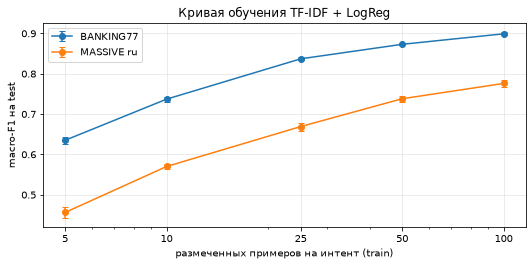

In [17]:
rng = np.random.default_rng(SEED)
rows = []
for name, tr, te in [("BANKING77", tr_b, te_b), ("MASSIVE ru", tr_r, te_r)]:
    for n in [5, 10, 25, 50, 100]:
        for rep in range(3):
            sub = tr.sample(frac=1, random_state=SEED + rep).groupby("intent").head(n)
            p = tfidf_lr(sub, te)
            rows.append(
                {
                    "датасет": name,
                    "n_на_интент": n,
                    "rep": rep,
                    "macro_f1": f1_score(te["intent"], p, average="macro"),
                }
            )
lc = (
    pd.DataFrame(rows).groupby(["датасет", "n_на_интент"])["macro_f1"].agg(["mean", "std"]).round(3)
)
print(lc)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for name, g in lc.reset_index().groupby("датасет"):
    ax.errorbar(g["n_на_интент"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=name)
ax.set_xscale("log")
ax.set_xticks([5, 10, 25, 50, 100], ["5", "10", "25", "50", "100"])
ax.set_xlabel("размеченных примеров на интент (train)")
ax.set_ylabel("macro-F1 на test")
ax.set_title("Кривая обучения TF-IDF + LogReg")
ax.legend()
save(fig, "05_learning_curve.png")

**Выводы.**
- Macro-F1 на BANKING77 растёт с 0,635 при 5 примерах на интент до 0,837 при 25, 0,873 при 50 и 0,899 при 100. На MASSIVE ru — с 0,456 до 0,669, 0,738 и 0,776. Основной прирост приходится на участок до 25–50 примеров. Плановые 50–100 кейсов на интент из BRD попадают в зону, где добавочная разметка ещё даёт эффект, но уже не кратный.
- Мы не обучаем модель на разметке, но эта кривая показывает **разнообразие формулировок** внутри интента: на 5–10 примерах видна лишь часть способов спросить одно и то же. Для LLM-судьи это значит, что примеры для промпта (few-shot) берём из первых данных Полины, а проверяем судью на полном наборе.

## 4. Качество разметки: согласие разметчиков (MASSIVE ru)

Оценок всего: 49563 | разметчиков на пример: [3]
intent_score (1 = интент верный, 0 = неверный, 2 = другое по инструкции MASSIVE): {1: 46700, 2: 1533, 0: 1330}
spelling_score: {2: 48206, 1: 1309, 0: 48}
language_identification: {'target': 46518, 'target|english': 3026, 'english': 18, 'target|other': 1}

Сколько из 3 проверяющих подтвердили интент: {3: 14139, 2: 1952, 1: 379, 0: 51}
Единогласно: 85.6%, большинство против (<=1 из 3): 2.6%

Интенты с наименьшей долей единогласия:
intent
lists_createoradd      0.506
lists_remove           0.561
email_querycontact     0.592
iot_hue_lighton        0.633
general_quirky         0.651
music_likeness         0.661
iot_hue_lightchange    0.721
cooking_recipe         0.731


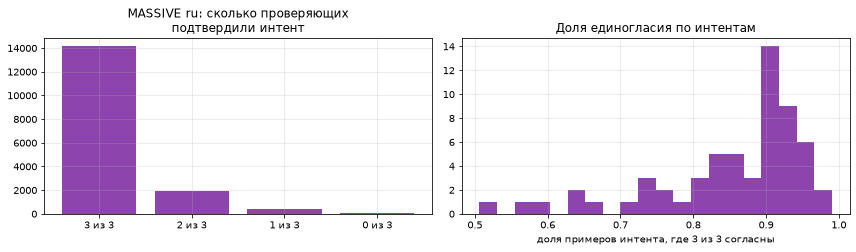

In [18]:
j = pd.json_normalize(ru["judgments"].explode().tolist())
print("Оценок всего:", len(j), "| разметчиков на пример:", ru["judgments"].map(len).unique())
print(
    "intent_score (1 = интент верный, 0 = неверный, 2 = другое по инструкции MASSIVE):",
    j["intent_score"].value_counts().to_dict(),
)
print("spelling_score:", j["spelling_score"].value_counts().to_dict())
print("language_identification:", j["language_identification"].value_counts().to_dict())

ru["n_intent_ok"] = ru["judgments"].map(lambda js: sum(x["intent_score"] == 1 for x in js))
agree = ru["n_intent_ok"].value_counts().sort_index(ascending=False)
print("\nСколько из 3 проверяющих подтвердили интент:", agree.to_dict())
print(
    f"Единогласно: {(ru['n_intent_ok'] == 3).mean():.1%}, большинство против (<=1 из 3): {(ru['n_intent_ok'] <= 1).mean():.1%}"
)

by_int = ru.groupby("intent")["n_intent_ok"].apply(lambda s: (s == 3).mean()).sort_values()
print("\nИнтенты с наименьшей долей единогласия:")
print(by_int.head(8).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar([f"{k} из 3" for k in agree.index], agree.values, color="#8e44ad")
ax[0].set_title("MASSIVE ru: сколько проверяющих\nподтвердили интент")
ax[1].hist(by_int.values, bins=20, color="#8e44ad")
ax[1].set_title("Доля единогласия по интентам")
ax[1].set_xlabel("доля примеров интента, где 3 из 3 согласны")
save(fig, "06_annotator_agreement.png")

**Выводы.**
- Даже в выверенном публичном датасете все три проверяющих подтвердили интент только в 85,6% примеров, в 2,6% большинство его отвергло. У худших интентов доля единогласия падает до 51–59% (`lists_createoradd`, `lists_remove`, `email_querycontact`). Ручная разметка банка тоже не будет «идеальной правдой».
- **Для критерия успеха:** доля совпадений судьи с разметкой ограничена сверху согласием самих разметчиков. Поэтому нужен поднабор с **двойной разметкой** (два человека независимо), чтобы измерить согласие человек–человек и сравнивать с ним согласие судья–человек. Без этого нельзя понять, 85% совпадений — это плохо или это потолок.

## 5. Синтетическая выдача: метрики и детектор просадок

> **Данные этого раздела полностью синтетические.** 20 интентов по 50 запросов, выдача из 8 фич. У каждого интента одна целевая фича (релевантность 2) и две смежные (релевантность 1). Затем имитируется релиз: у 10% запросов целевая фича съезжает на 3 позиции вниз. Судья имитируется случайной заменой оценки позиции с заданной долей ошибок. Цель — понять поведение метрик, а не получить реальные цифры.

In [19]:
base = make_serp()
cur, hit = inject_release(base, share_queries=0.1, shift=3)
mb, mc = query_metrics(base), query_metrics(cur)
cmp = mb.merge(mc, on=["query", "intent"], suffixes=("_base", "_cur"))
cmp["hit"] = cmp["query"].isin(hit)
print("Запросов:", len(cmp), "| с внесённой просадкой:", len(hit))
print(cmp.groupby("hit")[["r3_base", "r3_cur", "ndcg3_base", "ndcg3_cur"]].mean().round(3))
top3_lost = cur[(cur["relevance"] == 2) & (cur["position"] > 3)]["query"].nunique()
print("Запросов, где целевая фича выпала из топ-3:", top3_lost)

Запросов: 1000 | с внесённой просадкой: 100
       r3_base  r3_cur  ndcg3_base  ndcg3_cur
hit                                          
False      1.0   1.000       0.950      0.950
True       1.0   0.667       0.957      0.395
Запросов, где целевая фича выпала из топ-3: 100


 error_rate  threshold  flagged  tp  precision  recall
       0.00        0.1      100 100      1.000    1.00
       0.00        0.2      100 100      1.000    1.00
       0.00        0.3      100 100      1.000    1.00
       0.05        0.1      184  98      0.533    0.98
       0.05        0.2      156  97      0.622    0.97
       0.05        0.3      108  91      0.843    0.91
       0.10        0.1      262  95      0.363    0.95
       0.10        0.2      206  91      0.442    0.91
       0.10        0.3      120  82      0.683    0.82
       0.20        0.1      324  80      0.247    0.80
       0.20        0.2      227  71      0.313    0.71
       0.20        0.3      138  60      0.435    0.60


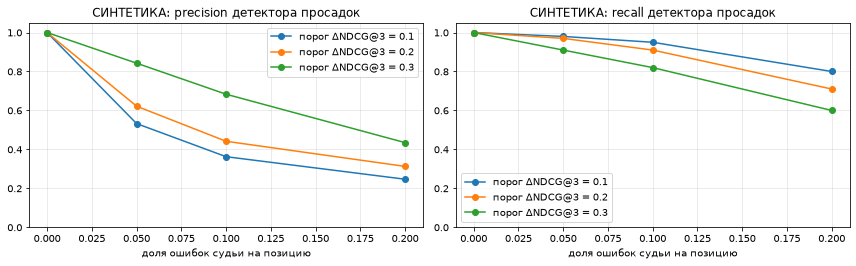

In [20]:
res = pd.DataFrame(
    [
        drop_detection_quality(base, cur, hit, e, t)
        for e in [0.0, 0.05, 0.1, 0.2]
        for t in [0.1, 0.2, 0.3]
    ]
)
print(res.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for t, g in res.groupby("threshold"):
    ax[0].plot(g["error_rate"], g["precision"], marker="o", label=f"порог ΔNDCG@3 = {t}")
    ax[1].plot(g["error_rate"], g["recall"], marker="o", label=f"порог ΔNDCG@3 = {t}")
ax[0].set_title("СИНТЕТИКА: precision детектора просадок")
ax[1].set_title("СИНТЕТИКА: recall детектора просадок")
for a in ax:
    a.set_xlabel("доля ошибок судьи на позицию")
    a.set_ylim(0, 1.05)
    a.legend()
save(fig, "07_synthetic_drop_detection.png")

**Выводы (на синтетике).**
- **R3 грубее NDCG@3.** На запросах с просадкой R3 падает с 1,0 до 0,667, а NDCG@3 — с 0,957 до 0,395. R3 меняется шагами по 1/3 и не различает, ушла из топ-3 целевая фича или смежная. NDCG@3 с градуированной релевантностью и прямая проверка «целевая фича в топ-3» отражают BR-1 точнее. Поэтому нужны оценки по позициям со шкалой, а не только бинарный вердикт по выдаче.
- **Ошибки судьи превращаются в ложные тревоги.** Шум в оценках срабатывает в обоих прогонах. При 5% ошибок на позицию и пороге ΔNDCG@3 = 0,2 precision детектора — 0,62, при 10% — 0,44. Порог 0,3 поднимает precision до 0,84 и 0,68, но recall падает до 0,91 и 0,82.
- **Что делаем в системе.** (1) Просадку по запросу подтверждаем фактом изменения выдачи: сравниваем снятые списки фич двух прогонов, а не только вердикты судьи. Если список не изменился, вердикт не мог «просесть». (2) Агрегируем по интенту. (3) Кэшируем вердикты для неизменившихся пар «запрос и выдача», чтобы шум судьи не накапливался между прогонами.

## 6. Размер проверочного набора для критерия успеха

доля совпадений p    0.8    0.9
n точек                        
30                 0.139  0.111
50                 0.109  0.085
100                0.078  0.060
200                0.055  0.042
500                0.035  0.026
1000               0.025  0.019
2000               0.018  0.013


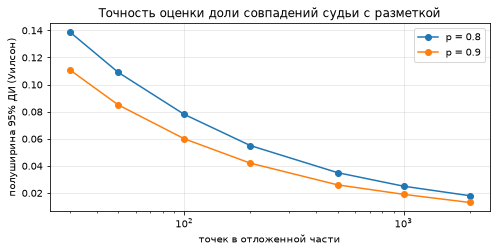

In [21]:
rows = []
for p in [0.8, 0.9]:
    for n in [30, 50, 100, 200, 500, 1000, 2000]:
        rows.append(
            {"доля совпадений p": p, "n точек": n, "±95% ДИ": round(wilson_halfwidth(p, n), 3)}
        )
ci = pd.DataFrame(rows).pivot(index="n точек", columns="доля совпадений p", values="±95% ДИ")
print(ci)

fig, ax = plt.subplots(figsize=(7, 3.6))
for p in ci.columns:
    ax.plot(ci.index, ci[p], marker="o", label=f"p = {p}")
ax.set_xscale("log")
ax.set_xlabel("точек в отложенной части")
ax.set_ylabel("полуширина 95% ДИ (Уилсон)")
ax.set_title("Точность оценки доли совпадений судьи с разметкой")
ax.legend()
save(fig, "08_holdout_size_ci.png")

**Выводы.**
- При 50 точках на интент доля совпадений по отдельному интенту известна с точностью ±8,5–11 п. п. (для p = 0,9 и 0,8). Этого хватает, чтобы найти явно проблемный интент, но мало, чтобы сравнивать две версии промпта по одному интенту.
- Для общего замера по всем интентам погрешность — ±1,9–2,5 п. п. при 1 000 точках и ±1,3–1,8 п. п. при 2 000. Отсюда правило: **итоговый критерий считаем по всему отложенному набору**, а по интентам смотрим только сильные отклонения.

## 7. Шаблон EDA для данных банка

Функции ниже запускаются на выгрузке банка в ожидаемом формате (одна строка — одна позиция выдачи): `run_id, platform, app_version, query, intent, position, feature, relevance, verdict, explanation`. Формат — **допущение** до ответа на вопрос В1. Загрузка — `mlsd_course.eda.loaders.load_bank_serp`. Пока данных нет, ячейка запускается на синтетике.

In [22]:
def bank_eda(serp: pd.DataFrame) -> dict:
    q = serp.drop_duplicates(["run_id", "platform", "app_version", "query"])
    per_intent = q.groupby("intent")["query"].nunique()
    top3 = serp[serp["position"] <= 3]
    return {
        "прогонов": serp["run_id"].nunique(),
        "платформ / версий": (serp["platform"].nunique(), serp["app_version"].nunique()),
        "запросов уникальных": serp["query"].nunique(),
        "интентов": serp["intent"].nunique(),
        "запросов на интент min/median/max": (
            per_intent.min(),
            per_intent.median(),
            per_intent.max(),
        ),
        "интентов с < 50 запросами": int((per_intent < 50).sum()),
        "средняя длина выдачи": serp.groupby(["run_id", "query"])["position"].max().mean(),
        "доля релевантных в топ-3": (top3["relevance"] > 0).mean(),
        "доля вердиктов not_ok": (q["verdict"] == "not_ok").mean(),
        "пустых объяснений": int(q["explanation"].fillna("").str.strip().eq("").sum()),
        "одинаковый текст с разными интентами": int(
            (serp.groupby(serp["query"].map(normalize))["intent"].nunique() > 1).sum()
        ),
    }


demo = base.assign(
    run_id="synthetic",
    platform="android",
    app_version="0.0-synthetic",
    verdict="ok",
    explanation="synthetic",
)
pd.Series(bank_eda(demo))

прогонов                                             1
платформ / версий                               (1, 1)
запросов уникальных                               1000
интентов                                            20
запросов на интент min/median/max       (50, 50.0, 50)
интентов с < 50 запросами                            0
средняя длина выдачи                               8.0
доля релевантных в топ-3                           1.0
доля вердиктов not_ok                              0.0
пустых объяснений                                    0
одинаковый текст с разными интентами                 0
dtype: object

## Итог: что EDA на прокси значит для проекта

1. **Объём разметки.** 50–100 кейсов на интент — разумный объём, но нужен минимум на каждый интент и стратификация, потому что распределение интентов имеет длинный хвост.
2. **Разбиение.** Делим по нормализованному тексту запроса, чтобы дубли не попадали в обе части. Стратифицируем по интенту, длине запроса и платформе.
3. **Шкала разметки.** Нужна градация по позициям (целевая, смежная, нерелевантная): R3 на бинарной шкале не отличает потерю целевой фичи от потери смежной.
4. **Рискованные интенты.** Это соседние продукты и состояния одного процесса. Для них — двойная разметка, явные правила приоритета в промпте судьи и отдельный отчёт по качеству.
5. **Потолок качества.** Разметчики расходятся даже в выверенных датасетах, поэтому согласие судьи сравниваем с согласием человек–человек на поднаборе с двойной разметкой.
6. **Язык.** Морфология, «ё/е», латиница, бренды и опечатки ломают строковый бейзлайн. В проверочный набор включаем такие запросы как отдельные страты.
7. **Детектор просадок.** Шум судьи даёт ложные тревоги. Просадку подтверждаем фактом изменения выдачи и агрегируем по интенту.